# ✅ PART A: Random Imputation for Numerical Column (Age)
# Dataset: Titanic (Age, Fare, Survived)

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [9]:
# 1) Load dataset
df = pd.read_csv('train.csv', usecols=['Age','Fare','Survived'])

print(df.head(), "\n")
print("✅ Missing %:\n", df.isnull().mean() * 100, "\n")

   Survived   Age     Fare
0         0  22.0   7.2500
1         1  38.0  71.2833
2         1  26.0   7.9250
3         1  35.0  53.1000
4         0  35.0   8.0500 

✅ Missing %:
 Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64 



In [10]:
# 2) Split X and y
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2
)

print("✅ X_train shape:", X_train.shape)
print("✅ X_test shape:", X_test.shape)
print("✅ Train missing Age:", X_train['Age'].isnull().sum())
print("✅ Test missing Age:", X_test['Age'].isnull().sum(), "\n")

# ✅ Fix: copy() to avoid SettingWithCopyWarning
X_train = X_train.copy()
X_test = X_test.copy()

✅ X_train shape: (712, 2)
✅ X_test shape: (179, 2)
✅ Train missing Age: 148
✅ Test missing Age: 29 



In [11]:
# 3) Create new column (copy original Age)
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']


In [12]:
# 4) Randomly sample values from NON-missing train Age and fill missing

train_missing_count = X_train['Age_imputed'].isnull().sum()
test_missing_count = X_test['Age_imputed'].isnull().sum()

# Take random samples from train non-missing values (ONLY TRAIN -> avoid leakage ✅)
random_train_values = X_train['Age'].dropna().sample(train_missing_count, random_state=42).values
random_test_values = X_train['Age'].dropna().sample(test_missing_count, random_state=42).values

# ✅ Fix: use loc (safe assignment)
X_train.loc[X_train['Age_imputed'].isnull(), 'Age_imputed'] = random_train_values
X_test.loc[X_test['Age_imputed'].isnull(), 'Age_imputed'] = random_test_values

print("✅ After Random Imputation:")
print("Train missing Age_imputed:", X_train['Age_imputed'].isnull().sum())
print("Test missing Age_imputed:", X_test['Age_imputed'].isnull().sum(), "\n")



✅ After Random Imputation:
Train missing Age_imputed: 0
Test missing Age_imputed: 0 



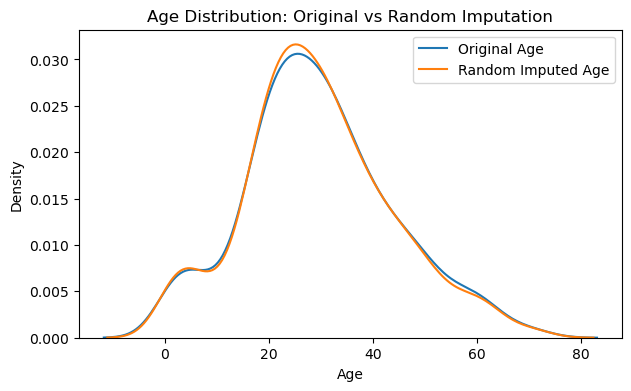

In [13]:
# 5) Distribution check (Original vs Imputed)
plt.figure(figsize=(7,4))
sns.kdeplot(X_train['Age'].dropna(), label="Original Age")
sns.kdeplot(X_train['Age_imputed'], label="Random Imputed Age")
plt.title("Age Distribution: Original vs Random Imputation")
plt.legend()
plt.show()


In [14]:
# 6) Variance check
print("✅ Original Age Variance:", X_train['Age'].var())
print("✅ Random Imputed Age Variance:", X_train['Age_imputed'].var(), "\n")


✅ Original Age Variance: 204.3495133904614
✅ Random Imputed Age Variance: 200.02896637747125 



In [15]:
# 7) Covariance check
print("✅ Covariance:")
print(X_train[['Fare', 'Age', 'Age_imputed']].cov(), "\n")


✅ Covariance:
                    Fare         Age  Age_imputed
Fare         2368.246832   71.512440    53.259863
Age            71.512440  204.349513   204.349513
Age_imputed    53.259863  204.349513   200.028966 



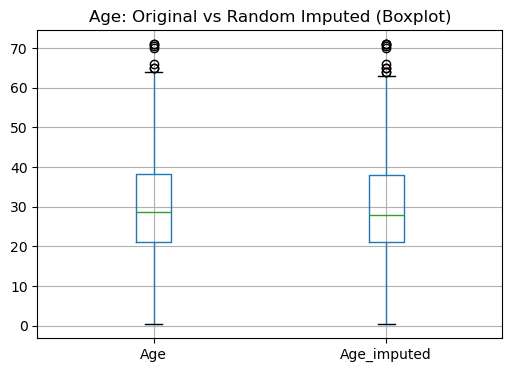

In [16]:
# 8) Boxplot check
plt.figure(figsize=(6,4))
X_train[['Age', 'Age_imputed']].boxplot()
plt.title("Age: Original vs Random Imputed (Boxplot)")
plt.show()

# ✅ PART B: Random Imputation for Categorical Columns
# Dataset: House Prices (GarageQual, FireplaceQu, SalePrice)

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [18]:
# 1) Load dataset
data = pd.read_csv('house.csv', usecols=['GarageQual','FireplaceQu', 'SalePrice'])

print(data.head(), "\n")
print("✅ Missing %:\n", data.isnull().mean() * 100, "\n")


  FireplaceQu GarageQual  SalePrice
0         NaN         TA     208500
1          TA         TA     181500
2          TA         TA     223500
3          Gd         TA     140000
4          TA         TA     250000 

✅ Missing %:
 FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64 



In [19]:
# 2) Split train/test
X = data[['GarageQual','FireplaceQu','SalePrice']]   # keep SalePrice for analysis
y = data['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2
)

# ✅ Fix: copy() to avoid SettingWithCopyWarning
X_train = X_train.copy()
X_test = X_test.copy()

In [20]:
# 3) Create new imputed columns (copy original)
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

print("✅ Train missing GarageQual:", X_train['GarageQual'].isnull().sum())
print("✅ Train missing FireplaceQu:", X_train['FireplaceQu'].isnull().sum(), "\n")

✅ Train missing GarageQual: 65
✅ Train missing FireplaceQu: 557 



In [21]:
# 4) Fill GarageQual missing using random values from TRAIN non-missing
train_garage_missing = X_train['GarageQual_imputed'].isnull().sum()
test_garage_missing = X_test['GarageQual_imputed'].isnull().sum()

rand_garage_train = X_train['GarageQual'].dropna().sample(train_garage_missing, random_state=42).values
rand_garage_test = X_train['GarageQual'].dropna().sample(test_garage_missing, random_state=42).values

X_train.loc[X_train['GarageQual_imputed'].isnull(), 'GarageQual_imputed'] = rand_garage_train
X_test.loc[X_test['GarageQual_imputed'].isnull(), 'GarageQual_imputed'] = rand_garage_test


In [22]:
# 5) Fill FireplaceQu missing using random values from TRAIN non-missing
train_fire_missing = X_train['FireplaceQu_imputed'].isnull().sum()
test_fire_missing = X_test['FireplaceQu_imputed'].isnull().sum()

rand_fire_train = X_train['FireplaceQu'].dropna().sample(train_fire_missing, random_state=42).values
rand_fire_test = X_train['FireplaceQu'].dropna().sample(test_fire_missing, random_state=42).values

X_train.loc[X_train['FireplaceQu_imputed'].isnull(), 'FireplaceQu_imputed'] = rand_fire_train
X_test.loc[X_test['FireplaceQu_imputed'].isnull(), 'FireplaceQu_imputed'] = rand_fire_test

print("✅ After Imputation:")
print("Train missing GarageQual_imputed:", X_train['GarageQual_imputed'].isnull().sum())
print("Train missing FireplaceQu_imputed:", X_train['FireplaceQu_imputed'].isnull().sum(), "\n")


✅ After Imputation:
Train missing GarageQual_imputed: 0
Train missing FireplaceQu_imputed: 0 



In [23]:
# ==========================================================
# 6) Compare category proportions (Original vs Imputed)
# ==========================================================

garage_compare = pd.concat(
    [
        # Original distribution without missing
        X_train['GarageQual'].value_counts(normalize=True, dropna=True),

        # Imputed distribution (now no missing)
        X_train['GarageQual_imputed'].value_counts(normalize=True, dropna=False)
    ],
    axis=1
)
garage_compare.columns = ['original', 'imputed']

print("✅ GarageQual proportions (original vs imputed):")
print(garage_compare, "\n")


fire_compare = pd.concat(
    [
        X_train['FireplaceQu'].value_counts(normalize=True, dropna=True),
        X_train['FireplaceQu_imputed'].value_counts(normalize=True, dropna=False)
    ],
    axis=1
)
fire_compare.columns = ['original', 'imputed']

print("✅ FireplaceQu proportions (original vs imputed):")
print(fire_compare, "\n")

✅ GarageQual proportions (original vs imputed):
    original   imputed
TA  0.951043  0.952055
Fa  0.037171  0.036815
Gd  0.009973  0.009418
Po  0.000907  0.000856
Ex  0.000907  0.000856 

✅ FireplaceQu proportions (original vs imputed):
    original   imputed
Gd  0.494272  0.500000
TA  0.412439  0.406678
Fa  0.040917  0.040240
Po  0.027823  0.028253
Ex  0.024550  0.024829 



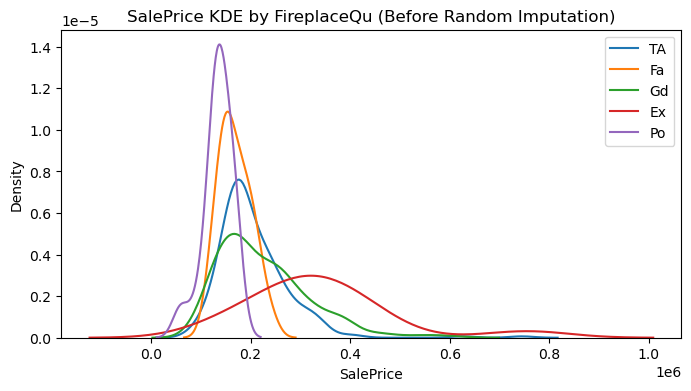

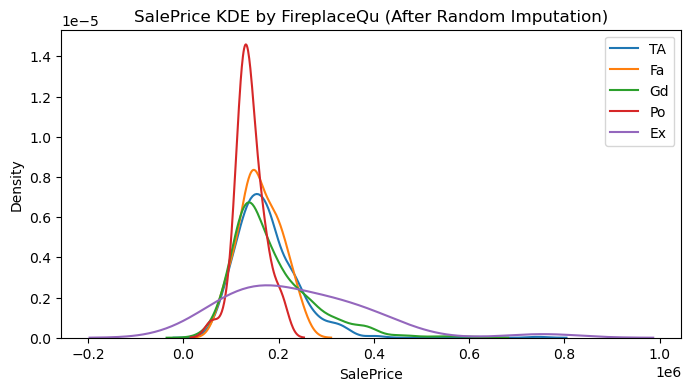

In [24]:
# 7) SalePrice distribution per category BEFORE and AFTER
# ==========================================================

plt.figure(figsize=(8,4))
for category in X_train['FireplaceQu'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'], label=str(category))
plt.title("SalePrice KDE by FireplaceQu (Before Random Imputation)")
plt.legend()
plt.show()

plt.figure(figsize=(8,4))
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'], label=str(category))
plt.title("SalePrice KDE by FireplaceQu (After Random Imputation)")
plt.legend()
plt.show()